In [ ]:
# --- Imports ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report
)

import warnings
warnings.filterwarnings('ignore')  # keeps the notebook output clean

np.set_printoptions(precision=4, suppress=True)
plt.rcParams['figure.figsize'] = (6, 5)


## 1. The Dataset: Iris

A classic, simple dataset: 150 flowers, 4 numeric features (sepal/petal length & width), and 3 species to predict — **setosa**, **versicolor**, **virginica**. It's balanced (50 of each), small, and easy to reason about.


In [ ]:
iris = load_iris()
X, y = iris.data, iris.target
feature_names = iris.feature_names
target_names = iris.target_names

# Peek at the data as a DataFrame
df = pd.DataFrame(X, columns=feature_names)
df['species'] = [target_names[i] for i in y]
print("Shape:", X.shape, " Classes:", target_names)
print("Class counts:", np.bincount(y))
df.head()


Shape: (150, 4)  Classes: ['setosa' 'versicolor' 'virginica']
Class counts: [50 50 50]


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


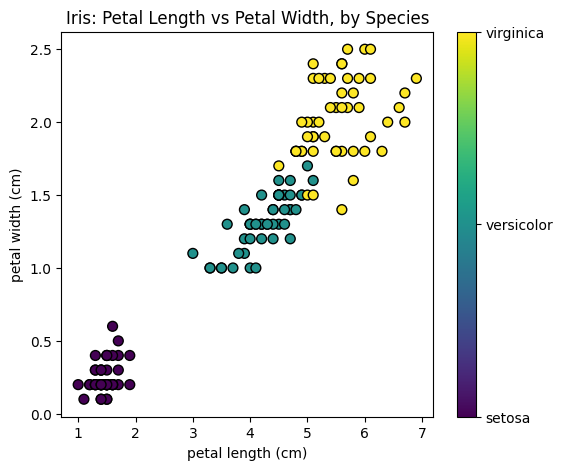

In [ ]:

plt.scatter(X[:, 2], X[:, 3], c=y, cmap='viridis', s=50, edgecolor='k')
plt.xlabel(feature_names[2])
plt.ylabel(feature_names[3])
plt.title('Iris: Petal Length vs Petal Width, by Species')
cbar = plt.colorbar(ticks=[0, 1, 2])
cbar.ax.set_yticklabels(target_names)
plt.show()


## 2. Train/Test Split

We hold out 30% of the data purely for testing — the model never sees these rows during training. `stratify=y` keeps the same class proportions in both the train and test sets.


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,      # 30% of the data reserved for testing
    random_state=42,     # makes the split reproducible
    stratify=y            # keep class proportions equal in train and test
)

print("Training samples:", X_train.shape[0])
print("Testing samples: ", X_test.shape[0])
print("Test set class counts:", np.bincount(y_test), "(still balanced, 15/15/15)")


Training samples: 105
Testing samples:  45
Test set class counts: [15 15 15] (still balanced, 15/15/15)


## 3. Train the Logistic Regression Model

scikit-learn automatically handles the multiclass case (3 species) using softmax under the hood — no extra code needed beyond `.fit()`.


In [ ]:
clf = LogisticRegression(max_iter=200)
clf.fit(X_train, y_train)

print("Model trained.")
print("Classes learned (in this order):", clf.classes_)
print("Coefficient shape:", clf.coef_.shape, " (one row of coefficients per class)")


Model trained.
Classes learned (in this order): [0 1 2]
Coefficient shape: (3, 4)  (one row of coefficients per class)


## 4. Predict on the Test Set

This is the moment of truth — predictions on data the model has never seen.


In [ ]:
y_pred = clf.predict(X_test)

results = pd.DataFrame({
    'Actual': [target_names[i] for i in y_test],
    'Predicted': [target_names[i] for i in y_pred],
    'Correct?': np.where(y_test == y_pred, '✓', '✗')
})
results


,Actual,Predicted,Correct?
0,virginica,virginica,✓
1,versicolor,versicolor,✓
2,virginica,versicolor,✗
3,versicolor,versicolor,✓
4,virginica,virginica,✓
5,virginica,virginica,✓
6,versicolor,versicolor,✓
7,versicolor,versicolor,✓
8,setosa,setosa,✓
9,virginica,virginica,✓


## 5. Confusion Matrix

The confusion matrix shows exactly WHERE the model gets confused — which species get mistaken for which.


Confusion Matrix (rows = actual, columns = predicted):
[[15  0  0]
 [ 0 14  1]
 [ 0  2 13]]


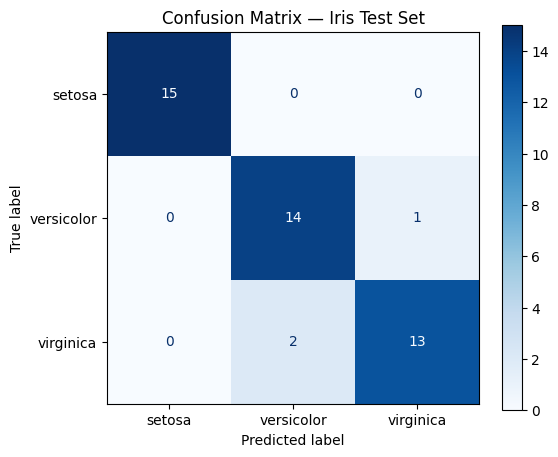

In [ ]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix (rows = actual, columns = predicted):")
print(cm)

# Visualize it
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix — Iris Test Set')
plt.show()


## 6. Accuracy

The simplest metric: what fraction of predictions were correct overall?


In [ ]:
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy = {acc:.4f}  ({acc*100:.1f}% of test predictions were correct)")


Accuracy = 0.9333  (93.3% of test predictions were correct)


## 7. Precision, Recall, F1 — Per Class

Accuracy alone can hide problems. These three metrics look at each class individually:

- **Precision**: of everything predicted as class X, how much actually WAS class X?
- **Recall**: of everything that actually IS class X, how much did we correctly catch?
- **F1-score**: the harmonic mean of precision and recall — a single number balancing both.


In [ ]:
precision_per_class = precision_score(y_test, y_pred, average=None)
recall_per_class = recall_score(y_test, y_pred, average=None)
f1_per_class = f1_score(y_test, y_pred, average=None)
support = np.bincount(y_test)   # how many TEST examples of each class

per_class_df = pd.DataFrame({
    'Class': target_names,
    'Precision': precision_per_class.round(3),
    'Recall': recall_per_class.round(3),
    'F1-score': f1_per_class.round(3),
    'Support': support
})
per_class_df


,Class,Precision,Recall,F1-score,Support
0,setosa,1.000,1.000,1.000,15
1,versicolor,0.875,0.933,0.903,15
2,virginica,0.929,0.867,0.897,15


## 8. Macro vs. Weighted Averages — What's the Difference?

We often want ONE overall number instead of one-per-class. There are two common ways to average:

$$\text{Macro average} = \frac{1}{K}\sum_{k=1}^{K} \text{metric}_k \qquad \text{(simple average — every class counts equally)}$$

$$\text{Weighted average} = \sum_{k=1}^{K} \frac{n_k}{N}\cdot \text{metric}_k \qquad \text{(weighted by how many test examples that class had)}$$

**Macro** treats a rare class exactly as important as a common one. **Weighted** lets common classes dominate the average, proportional to their size.


In [ ]:
# scikit-learn computes both directly with the `average` parameter
precision_macro = precision_score(y_test, y_pred, average='macro')
precision_weighted = precision_score(y_test, y_pred, average='weighted')

recall_macro = recall_score(y_test, y_pred, average='macro')
recall_weighted = recall_score(y_test, y_pred, average='weighted')

f1_macro = f1_score(y_test, y_pred, average='macro')
f1_weighted = f1_score(y_test, y_pred, average='weighted')

summary_df = pd.DataFrame({
    'Metric': ['Precision', 'Recall', 'F1-score'],
    'Macro Average': [precision_macro, recall_macro, f1_macro],
    'Weighted Average': [precision_weighted, recall_weighted, f1_weighted]
}).round(4)
summary_df


,Metric,Macro Average,Weighted Average
0,Precision,0.9345,0.9345
1,Recall,0.9333,0.9333
2,F1-score,0.9333,0.9333


In [ ]:
# Let's manually verify macro and weighted from the per-class numbers above --
# this demystifies exactly what scikit-learn is computing internally.

manual_macro_f1 = f1_per_class.mean()
manual_weighted_f1 = np.average(f1_per_class, weights=support)

print(f"Manual macro F1    = mean(F1 per class)                = {manual_macro_f1:.4f}")
print(f"Manual weighted F1 = sum(support_k/N * F1_k)            = {manual_weighted_f1:.4f}")
print(f"scikit-learn macro F1    = {f1_macro:.4f}   (matches!)")
print(f"scikit-learn weighted F1 = {f1_weighted:.4f}   (matches!)")
print()
print("On this BALANCED test set (15/15/15), macro and weighted come out nearly identical --")
print("every class has the same support, so weighting by support changes nothing.")


Manual macro F1    = mean(F1 per class)                = 0.9333
Manual weighted F1 = sum(support_k/N * F1_k)            = 0.9333
scikit-learn macro F1    = 0.9333   (matches!)
scikit-learn weighted F1 = 0.9333   (matches!)

On this BALANCED test set (15/15/15), macro and weighted come out nearly identical --
every class has the same support, so weighting by support changes nothing.


## 9. The Full `classification_report`

scikit-learn can print everything above — per-class metrics AND both averages — in one call.


In [ ]:
print(classification_report(y_test, y_pred, target_names=target_names))


              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.88      0.93      0.90        15
   virginica       0.93      0.87      0.90        15

    accuracy                           0.93        45
   macro avg       0.93      0.93      0.93        45
weighted avg       0.93      0.93      0.93        45



## 10. When Macro and Weighted Actually Differ: An Imbalanced Example

The averages matched above because our test set was perfectly balanced. Let's deliberately create an **imbalanced** version of Iris — keeping only 8 ‘virginica’ flowers (the species that's hardest to separate from ‘versicolor’) — and watch what happens.


In [ ]:
# Build an imbalanced dataset: only 8 virginica samples, all 50 of the other two species
rng = np.random.RandomState(7)
virginica_idx = np.where(y == 2)[0]
keep_virginica = rng.choice(virginica_idx, size=8, replace=False)
other_idx = np.where(y != 2)[0]
keep_idx = np.concatenate([keep_virginica, other_idx])

X_imb, y_imb = X[keep_idx], y[keep_idx]
print("Imbalanced class counts (setosa, versicolor, virginica):", np.bincount(y_imb))


Imbalanced class counts (setosa, versicolor, virginica): [50 50  8]


In [ ]:
# Same pipeline as before: split, train, predict
X_train_i, X_test_i, y_train_i, y_test_i = train_test_split(
    X_imb, y_imb, test_size=0.35, random_state=7, stratify=y_imb
)
print("Test set class counts:", np.bincount(y_test_i), " <- virginica is now rare (only 3 in the test set)")

clf_imb = LogisticRegression(max_iter=200)
clf_imb.fit(X_train_i, y_train_i)
y_pred_i = clf_imb.predict(X_test_i)

print("\nAccuracy:", round(accuracy_score(y_test_i, y_pred_i), 4))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_i, y_pred_i))


Test set class counts: [17 18  3]  <- virginica is now rare (only 3 in the test set)

Accuracy: 0.9474

Confusion Matrix:
[[17  0  0]
 [ 0 18  0]
 [ 0  2  1]]


In [ ]:
print(classification_report(y_test_i, y_pred_i, target_names=target_names, zero_division=0))

f1_macro_i = f1_score(y_test_i, y_pred_i, average='macro')
f1_weighted_i = f1_score(y_test_i, y_pred_i, average='weighted')

print(f"F1 macro    = {f1_macro_i:.4f}")
print(f"F1 weighted = {f1_weighted_i:.4f}")
print(f"Difference  = {abs(f1_macro_i - f1_weighted_i):.4f}")


              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        17
  versicolor       0.90      1.00      0.95        18
   virginica       1.00      0.33      0.50         3

    accuracy                           0.95        38
   macro avg       0.97      0.78      0.82        38
weighted avg       0.95      0.95      0.94        38

F1 macro    = 0.8158
F1 weighted = 0.9356
Difference  = 0.1198


**What just happened:** the model does poorly on the rare ‘virginica’ class (few training examples to learn from), but virginica barely affects the WEIGHTED average because it's such a small fraction of the test set. The MACRO average, on the other hand, treats virginica's poor score exactly as important as the other two classes — pulling the macro F1 down noticeably.

**Practical takeaway:** if you only look at accuracy or the weighted average, a model that's quietly failing on a rare (but possibly important) class can hide in plain sight. Always check the macro average — and the per-class breakdown — on imbalanced data.


## Summary

| Step | scikit-learn call |
|---|---|
| Split data | `train_test_split(X, y, test_size=..., stratify=y)` |
| Train | `LogisticRegression().fit(X_train, y_train)` |
| Predict | `clf.predict(X_test)` |
| Confusion matrix | `confusion_matrix(y_test, y_pred)` |
| Accuracy | `accuracy_score(y_test, y_pred)` |
| Precision/Recall/F1 (per class) | `precision_score(..., average=None)`, etc. |
| Macro average | `average='macro'` — simple mean across classes, every class weighted equally |
| Weighted average | `average='weighted'` — mean weighted by how many test examples each class had |
| Everything at once | `classification_report(y_test, y_pred, target_names=...)` |

**Key takeaway:** macro and weighted averages agree when classes are balanced, and diverge when they aren't — the gap between them is itself a useful diagnostic for spotting class imbalance problems.
